# TA-04: Peramalan Jumlah Gempa Bumi Signifikan Menggunakan LSTM

## Tahap 1 — Validasi Dataset

Dataset: Significant Earthquakes, 1965–2016 (USGS)

Tujuan:
1. Memeriksa struktur dataset.
2. Memeriksa kelengkapan data.
3. Memvalidasi format tanggal dan magnitudo.
4. Memfilter gempa bumi dengan magnitudo >= 5.5.
5. Mengubah data kejadian menjadi jumlah gempa per hari.
6. Memvisualisasikan hasil agregasi.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [2]:
PROJECT_DIR = Path(
    r"D:\Semester5 ML\TA-04-Earthquake-Forecasting"
)

RAW_FILE = PROJECT_DIR / "data" / "raw" / "database.csv"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Lokasi proyek:", PROJECT_DIR)
print("Dataset ditemukan:", RAW_FILE.exists())
print("Lokasi dataset:", RAW_FILE)

Lokasi proyek: D:\Semester5 ML\TA-04-Earthquake-Forecasting
Dataset ditemukan: True
Lokasi dataset: D:\Semester5 ML\TA-04-Earthquake-Forecasting\data\raw\database.csv


In [3]:
#cell 4 Memuat dataset
df = pd.read_csv(RAW_FILE)

print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))

display(df.head())

Jumlah baris: 23412
Jumlah kolom: 21


,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status
0,01/02/1965,13:44:18,19.246,145.616,Earthquake,131.6,NaN,NaN,6.0,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860706,ISCGEM,ISCGEM,ISCGEM,Automatic
1,01/04/1965,11:29:49,1.863,127.352,Earthquake,80.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860737,ISCGEM,ISCGEM,ISCGEM,Automatic
2,01/05/1965,18:05:58,-20.579,-173.972,Earthquake,20.0,NaN,NaN,6.2,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860762,ISCGEM,ISCGEM,ISCGEM,Automatic
3,01/08/1965,18:49:43,-59.076,-23.557,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860856,ISCGEM,ISCGEM,ISCGEM,Automatic
4,01/09/1965,13:32:50,11.938,126.427,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860890,ISCGEM,ISCGEM,ISCGEM,Automatic


In [4]:
#Cell 5 Memeriksa struktur dataset
print("Nama kolom:")
print(df.columns.tolist())

print("\nInformasi dataset:")
df.info()

Nama kolom:
['Date', 'Time', 'Latitude', 'Longitude', 'Type', 'Depth', 'Depth Error', 'Depth Seismic Stations', 'Magnitude', 'Magnitude Type', 'Magnitude Error', 'Magnitude Seismic Stations', 'Azimuthal Gap', 'Horizontal Distance', 'Horizontal Error', 'Root Mean Square', 'ID', 'Source', 'Location Source', 'Magnitude Source', 'Status']

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 23412 entries, 0 to 23411
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Date                        23412 non-null  str    
 1   Time                        23412 non-null  str    
 2   Latitude                    23412 non-null  float64
 3   Longitude                   23412 non-null  float64
 4   Type                        23412 non-null  str    
 5   Depth                       23412 non-null  float64
 6   Depth Error                 4461 non-null   float64
 7   Depth Seismic Stations     

In [5]:
#Cell 6 Memeriksa nilai kosong
missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    "Jumlah Missing": missing_values,
    "Persentase (%)": (missing_values / len(df) * 100).round(2)
})

display(missing_table)

,Jumlah Missing,Persentase (%)
Date,0,0.00
Time,0,0.00
Latitude,0,0.00
Longitude,0,0.00
Type,0,0.00
Depth,0,0.00
Depth Error,18951,80.95
Depth Seismic Stations,16315,69.69
Magnitude,0,0.00
Magnitude Type,3,0.01


In [6]:
#cell 7 Memeriksa duplikasi
print("Jumlah baris duplikat:", df.duplicated().sum())

Jumlah baris duplikat: 0


In [7]:
#cell 8 Memeriksa Jenis Kejadian
print(df["Type"].value_counts(dropna=False))

Type
Earthquake           23232
Nuclear Explosion      175
Explosion                4
Rock Burst               1
Name: count, dtype: int64


In [8]:
#cell 9 Memeriksa distribusi magnitudo
df["Magnitude"] = pd.to_numeric(
    df["Magnitude"],
    errors="coerce"
)

display(df["Magnitude"].describe())

count    23412.000000
mean         5.882531
std          0.423066
min          5.500000
25%          5.600000
50%          5.700000
75%          6.000000
max          9.100000
Name: Magnitude, dtype: float64

In [9]:

# Cell 10 - Memvalidasi Tanggal

df["Date_parsed"] = pd.to_datetime(
    df["Date"],
    format="mixed",
    errors="coerce",
    utc=True
)

print("Jumlah tanggal tidak valid:", df["Date_parsed"].isna().sum())

print("Tanggal paling awal:", df["Date_parsed"].min())
print("Tanggal paling akhir:", df["Date_parsed"].max())

display(
    df[["Date", "Date_parsed"]].head(10)
)


Jumlah tanggal tidak valid: 0
Tanggal paling awal: 1965-01-02 00:00:00+00:00
Tanggal paling akhir: 2016-12-30 00:00:00+00:00


,Date,Date_parsed
0,01/02/1965,1965-01-02 00:00:00+00:00
1,01/04/1965,1965-01-04 00:00:00+00:00
2,01/05/1965,1965-01-05 00:00:00+00:00
3,01/08/1965,1965-01-08 00:00:00+00:00
4,01/09/1965,1965-01-09 00:00:00+00:00
5,01/10/1965,1965-01-10 00:00:00+00:00
6,01/12/1965,1965-01-12 00:00:00+00:00
7,01/15/1965,1965-01-15 00:00:00+00:00
8,01/16/1965,1965-01-16 00:00:00+00:00
9,01/17/1965,1965-01-17 00:00:00+00:00


In [10]:
#cell 11 Memfilter data gempa
earthquake_df = df[
    (df["Type"].astype(str).str.strip().str.lower() == "earthquake")
    & (df["Magnitude"] >= 5.5)
    & (df["Date_parsed"].notna())
].copy()

earthquake_df = earthquake_df.drop_duplicates(
    subset=df.columns.drop("Date_parsed").tolist()
)

print("Jumlah data awal:", len(df))
print("Jumlah data setelah filter:", len(earthquake_df))

display(earthquake_df.head())

Jumlah data awal: 23412
Jumlah data setelah filter: 23232


,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status,Date_parsed
0,01/02/1965,13:44:18,19.246,145.616,Earthquake,131.6,NaN,NaN,6.0,MW,...,NaN,NaN,NaN,NaN,ISCGEM860706,ISCGEM,ISCGEM,ISCGEM,Automatic,1965-01-02 00:00:00+00:00
1,01/04/1965,11:29:49,1.863,127.352,Earthquake,80.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,ISCGEM860737,ISCGEM,ISCGEM,ISCGEM,Automatic,1965-01-04 00:00:00+00:00
2,01/05/1965,18:05:58,-20.579,-173.972,Earthquake,20.0,NaN,NaN,6.2,MW,...,NaN,NaN,NaN,NaN,ISCGEM860762,ISCGEM,ISCGEM,ISCGEM,Automatic,1965-01-05 00:00:00+00:00
3,01/08/1965,18:49:43,-59.076,-23.557,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,ISCGEM860856,ISCGEM,ISCGEM,ISCGEM,Automatic,1965-01-08 00:00:00+00:00
4,01/09/1965,13:32:50,11.938,126.427,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,ISCGEM860890,ISCGEM,ISCGEM,ISCGEM,Automatic,1965-01-09 00:00:00+00:00


In [11]:
#cell 12 Agregasi data gempa per harian
earthquake_df["Tanggal"] = (
    earthquake_df["Date_parsed"].dt.normalize()
)

daily_counts = (
    earthquake_df
    .groupby("Tanggal")
    .size()
    .rename("jumlah_gempa")
)

full_date_range = pd.date_range(
    start=daily_counts.index.min(),
    end=daily_counts.index.max(),
    freq="D"
)

daily_counts = daily_counts.reindex(
    full_date_range,
    fill_value=0
)

daily_df = daily_counts.rename_axis("tanggal").reset_index()

display(daily_df.head(10))

,tanggal,jumlah_gempa
0,1965-01-02 00:00:00+00:00,1
1,1965-01-03 00:00:00+00:00,0
2,1965-01-04 00:00:00+00:00,1
3,1965-01-05 00:00:00+00:00,1
4,1965-01-06 00:00:00+00:00,0
5,1965-01-07 00:00:00+00:00,0
6,1965-01-08 00:00:00+00:00,1
7,1965-01-09 00:00:00+00:00,1
8,1965-01-10 00:00:00+00:00,1
9,1965-01-11 00:00:00+00:00,0


In [12]:
#cell 13 statistik data harian
print("Jumlah hari:", len(daily_df))
print("Total gempa:", daily_df["jumlah_gempa"].sum())
print("Rata-rata gempa per hari:", daily_df["jumlah_gempa"].mean())
print("Median:", daily_df["jumlah_gempa"].median())
print("Hari tanpa gempa:", (daily_df["jumlah_gempa"] == 0).sum())
print("Hari dengan gempa:", (daily_df["jumlah_gempa"] > 0).sum())
print("Gempa terbanyak dalam sehari:", daily_df["jumlah_gempa"].max())

display(daily_df.describe())

Jumlah hari: 18991
Total gempa: 23232
Rata-rata gempa per hari: 1.2233163077247118
Median: 1.0
Hari tanpa gempa: 6655
Hari dengan gempa: 12336
Gempa terbanyak dalam sehari: 128


,jumlah_gempa
count,18991.000000
mean,1.223316
std,1.730224
min,0.000000
25%,0.000000
50%,1.000000
75%,2.000000
max,128.000000


In [13]:
#cell 17 Mencari 10 hari jumlah gempa terbanyak
top_days = daily_df.sort_values(
    by="jumlah_gempa",
    ascending=False
).head(10)

display(top_days)

,tanggal,jumlah_gempa
16869,2011-03-11 00:00:00+00:00,128
14603,2004-12-26 00:00:00+00:00,51
16492,2010-02-27 00:00:00+00:00,39
17567,2013-02-06 00:00:00+00:00,27
15292,2006-11-15 00:00:00+00:00,25
16870,2011-03-12 00:00:00+00:00,21
13102,2000-11-16 00:00:00+00:00,21
33,1965-02-04 00:00:00+00:00,19
10059,1992-07-18 00:00:00+00:00,17
11292,1995-12-03 00:00:00+00:00,15


In [14]:
#cell 18 Memeriksa detail kejadian pada hari dengan 128 gempa
max_count = daily_df["jumlah_gempa"].max()

max_date = daily_df.loc[
    daily_df["jumlah_gempa"].idxmax(),
    "tanggal"
]

print("Tanggal dengan gempa terbanyak:", max_date)
print("Jumlah gempa:", max_count)

detail_max_day = earthquake_df[
    earthquake_df["Tanggal"] == max_date
]

display(
    detail_max_day[
        ["Date", "Time", "Latitude", "Longitude",
         "Magnitude", "Type", "ID"]
    ].sort_values("Time")
)

Tanggal dengan gempa terbanyak: 2011-03-11 00:00:00+00:00
Jumlah gempa: 128


,Date,Time,Latitude,Longitude,Magnitude,Type,ID
20500,03/11/2011,00:14:48,-53.210,-117.837,5.7,Earthquake,USP000HVNG
20501,03/11/2011,05:46:24,38.297,142.373,9.1,Earthquake,OFFICIAL20110311054624120_30
20502,03/11/2011,05:54:32,37.712,141.184,6.3,Earthquake,USP000HVNV
20503,03/11/2011,05:55:45,37.359,143.351,6.4,Earthquake,USP000HVNW
20504,03/11/2011,05:58:07,37.623,142.155,6.3,Earthquake,USP000HVNX
...,...,...,...,...,...,...,...
20623,03/11/2011,19:46:51,40.483,139.055,6.2,Earthquake,USP000HW1Y
20624,03/11/2011,20:11:24,39.005,142.633,6.1,Earthquake,USP000HW29
20625,03/11/2011,20:23:41,35.814,141.605,5.7,Earthquake,USP000HW2F
20626,03/11/2011,20:36:10,37.829,142.828,5.5,Earthquake,USP000HW2N


In [15]:
#cell 19 Memeriksa distribusi nilai ekstrem
print("Persentil jumlah gempa harian:")

display(
    daily_df["jumlah_gempa"].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
    )
)

print("\nJumlah hari berdasarkan ambang batas:")

for batas in [5, 10, 20, 50, 100]:
    jumlah_hari = (
        daily_df["jumlah_gempa"] > batas
    ).sum()

    print(
        f"Hari dengan gempa > {batas}: {jumlah_hari}"
    )

Persentil jumlah gempa harian:


0.500     1.00
0.750     2.00
0.900     3.00
0.950     4.00
0.990     6.00
0.999    12.01
Name: jumlah_gempa, dtype: float64


Jumlah hari berdasarkan ambang batas:
Hari dengan gempa > 5: 232
Hari dengan gempa > 10: 31
Hari dengan gempa > 20: 7
Hari dengan gempa > 50: 2
Hari dengan gempa > 100: 1


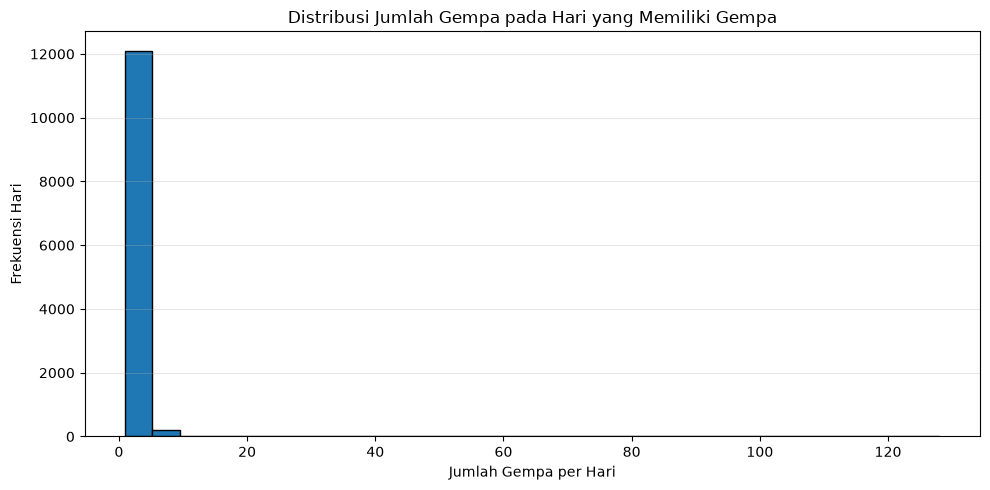

In [16]:
#cell 20 visualisasi distribusi tanpa hari bernilai nol
positive_counts = daily_df.loc[
    daily_df["jumlah_gempa"] > 0,
    "jumlah_gempa"
]

plt.figure(figsize=(10, 5))

plt.hist(
    positive_counts,
    bins=30,
    edgecolor="black"
)

plt.title("Distribusi Jumlah Gempa pada Hari yang Memiliki Gempa")
plt.xlabel("Jumlah Gempa per Hari")
plt.ylabel("Frekuensi Hari")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

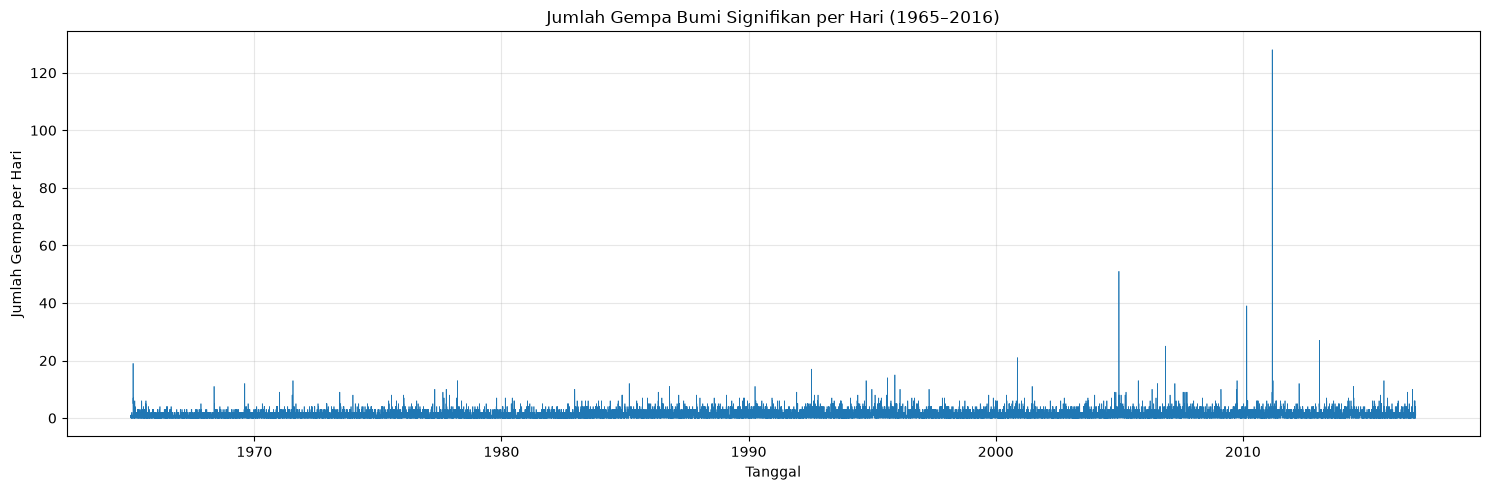

In [17]:
#cell 14 visualisasi jumlah gempa per hari
plt.figure(figsize=(15, 5))

plt.plot(
    daily_df["tanggal"],
    daily_df["jumlah_gempa"],
    linewidth=0.5
)

plt.title("Jumlah Gempa Bumi Signifikan per Hari (1965–2016)")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Gempa per Hari")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

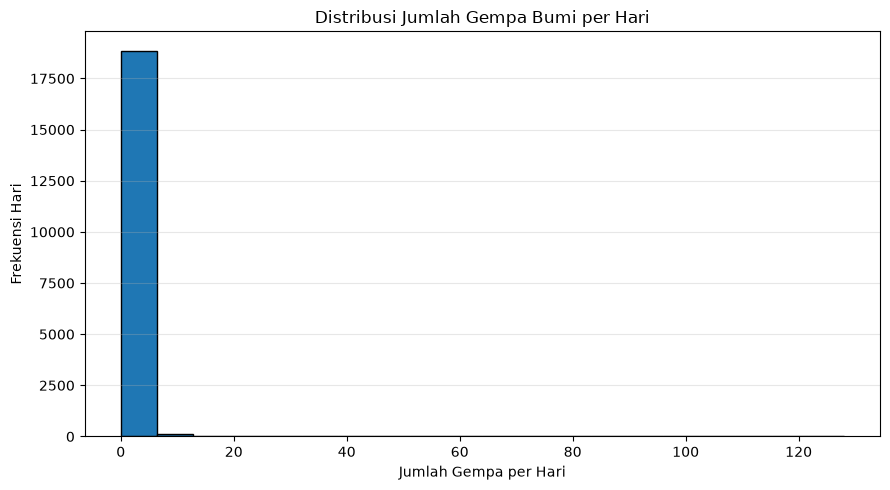

Persentase hari tanpa gempa: 35.04 %


In [18]:
#cell 15 visualisasi distribusi
plt.figure(figsize=(9, 5))

plt.hist(
    daily_df["jumlah_gempa"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribusi Jumlah Gempa Bumi per Hari")
plt.xlabel("Jumlah Gempa per Hari")
plt.ylabel("Frekuensi Hari")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print(
    "Persentase hari tanpa gempa:",
    round((daily_df["jumlah_gempa"] == 0).mean() * 100, 2),
    "%"
)

In [19]:
#cell 16 Menyimpan dataset yang sudah dibersihkan
OUTPUT_FILE = PROCESSED_DIR / "earthquake_daily_counts.csv"

daily_df.to_csv(OUTPUT_FILE, index=False)

print("Dataset harian berhasil disimpan:")
print(OUTPUT_FILE)

Dataset harian berhasil disimpan:
D:\Semester5 ML\TA-04-Earthquake-Forecasting\data\processed\earthquake_daily_counts.csv


# Tahap 2 — Exploratory Data Analysis (EDA)

Tujuan:
1. Menganalisis tren jumlah gempa.
2. Mengamati perubahan jumlah gempa dari waktu ke waktu.
3. Memeriksa distribusi jumlah gempa harian.
4. Mengidentifikasi pola dan karakteristik data time series.

In [20]:
#cell 21 Memastikan data berurutan berdasarkan tanggal
daily_df = daily_df.sort_values("tanggal").reset_index(drop=True)

print("Jumlah baris:", len(daily_df))
print("Tanggal awal:", daily_df["tanggal"].min())
print("Tanggal akhir:", daily_df["tanggal"].max())

print(
    "Apakah tanggal berurutan?",
    daily_df["tanggal"].diff().dropna().eq(pd.Timedelta(days=1)).all()
)

print(
    "Apakah terdapat nilai negatif?",
    (daily_df["jumlah_gempa"] < 0).any()
)

Jumlah baris: 18991
Tanggal awal: 1965-01-02 00:00:00+00:00
Tanggal akhir: 2016-12-30 00:00:00+00:00
Apakah tanggal berurutan? True
Apakah terdapat nilai negatif? False


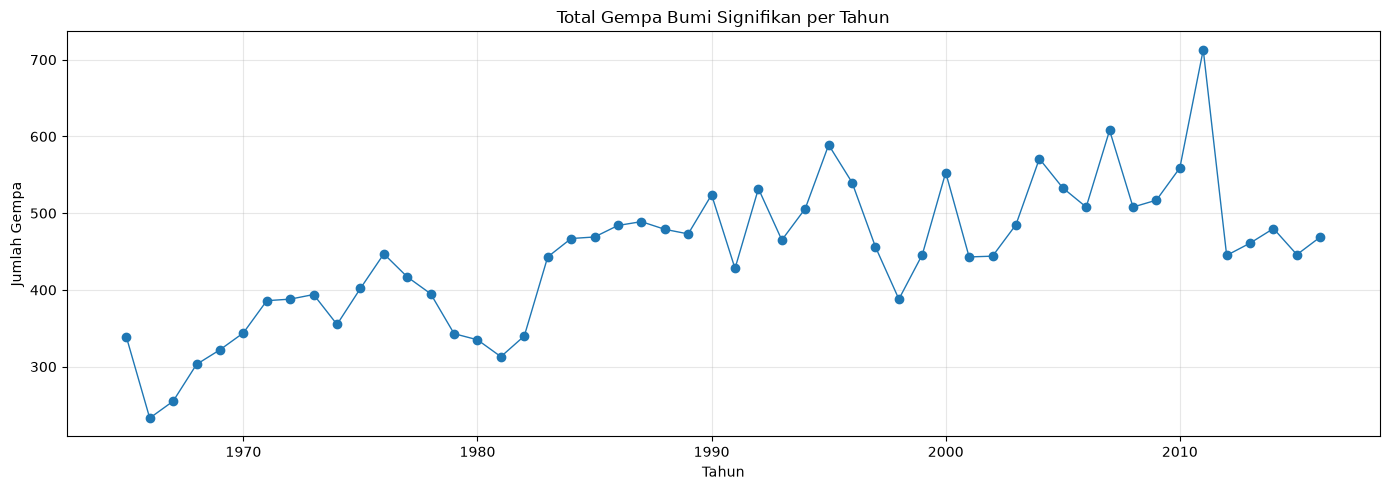

count     52.000000
mean     446.769231
std       92.078742
min      233.000000
25%      388.000000
50%      451.500000
75%      506.500000
max      713.000000
Name: jumlah_gempa, dtype: float64

In [21]:
#Cell 22 — Grafik jumlah gempa tahunan
yearly_df = (
    daily_df
    .set_index("tanggal")["jumlah_gempa"]
    .resample("YE")
    .sum()
)

plt.figure(figsize=(14, 5))

plt.plot(
    yearly_df.index.year,
    yearly_df.values,
    marker="o",
    linewidth=1
)

plt.title("Total Gempa Bumi Signifikan per Tahun")
plt.xlabel("Tahun")
plt.ylabel("Jumlah Gempa")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

display(yearly_df.describe())

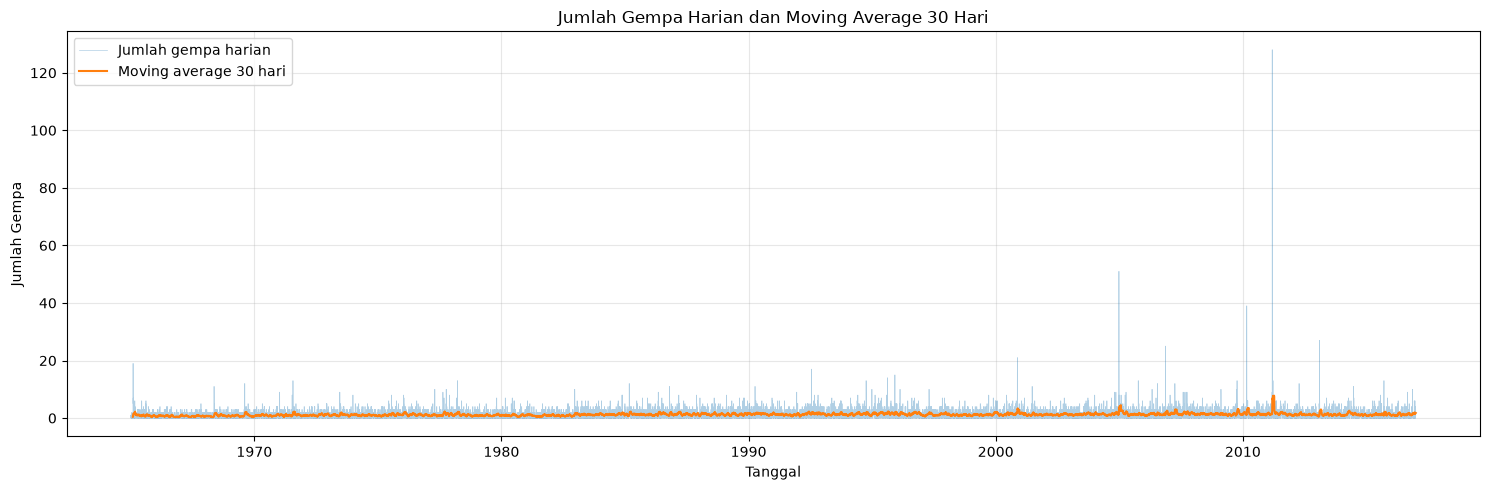

In [22]:
#Cell 23 — Tren menggunakan moving average 30 hari
daily_df["moving_average_30"] = (
    daily_df["jumlah_gempa"]
    .rolling(window=30)
    .mean()
)

plt.figure(figsize=(15, 5))

plt.plot(
    daily_df["tanggal"],
    daily_df["jumlah_gempa"],
    alpha=0.35,
    linewidth=0.5,
    label="Jumlah gempa harian"
)

plt.plot(
    daily_df["tanggal"],
    daily_df["moving_average_30"],
    linewidth=1.5,
    label="Moving average 30 hari"
)

plt.title("Jumlah Gempa Harian dan Moving Average 30 Hari")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Gempa")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

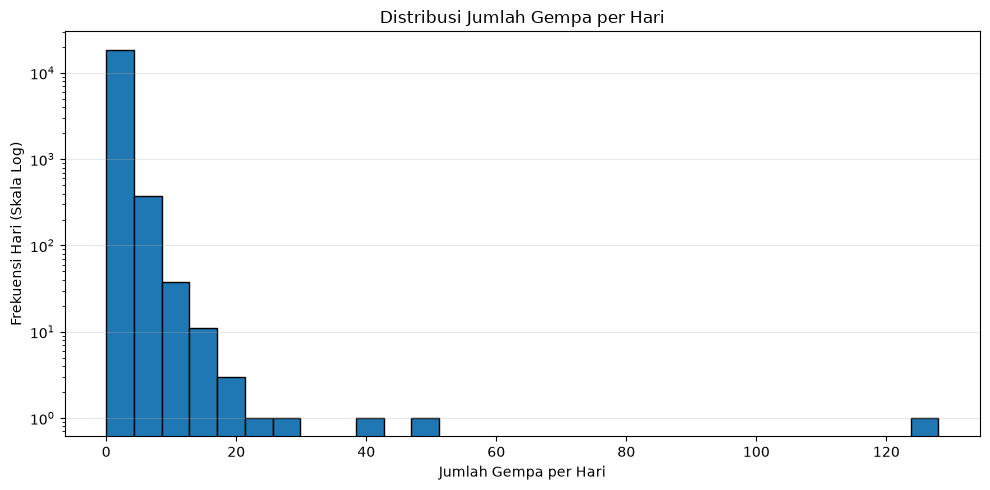

In [23]:
#Cell 24 — Distribusi jumlah gempa harian
plt.figure(figsize=(10, 5))

plt.hist(
    daily_df["jumlah_gempa"],
    bins=30,
    edgecolor="black"
)

plt.yscale("log")

plt.title("Distribusi Jumlah Gempa per Hari")
plt.xlabel("Jumlah Gempa per Hari")
plt.ylabel("Frekuensi Hari (Skala Log)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
#Cell 25 — Ringkasan karakteristik time series
total_days = len(daily_df)

zero_days = (
    daily_df["jumlah_gempa"] == 0
).sum()

nonzero_days = (
    daily_df["jumlah_gempa"] > 0
).sum()

print("RINGKASAN TIME SERIES")
print("-" * 40)
print("Total hari:", total_days)
print("Hari tanpa gempa:", zero_days)
print("Hari dengan gempa:", nonzero_days)

print(
    "Persentase hari tanpa gempa:",
    round(zero_days / total_days * 100, 2),
    "%"
)

print(
    "Persentase hari dengan gempa:",
    round(nonzero_days / total_days * 100, 2),
    "%"
)

print(
    "Rata-rata jumlah gempa:",
    round(daily_df["jumlah_gempa"].mean(), 4)
)

print(
    "Standar deviasi:",
    round(daily_df["jumlah_gempa"].std(), 4)
)

RINGKASAN TIME SERIES
----------------------------------------
Total hari: 18991
Hari tanpa gempa: 6655
Hari dengan gempa: 12336
Persentase hari tanpa gempa: 35.04 %
Persentase hari dengan gempa: 64.96 %
Rata-rata jumlah gempa: 1.2233
Standar deviasi: 1.7302


# TAHAP 3 - PREPROCESSING DATA

Pada tahap ini dilakukan persiapan data sebelum digunakan untuk
melatih model LSTM.

Data dibagi secara kronologis menjadi:
- 80% data training
- 10% data validation
- 10% data testing

Normalisasi menggunakan MinMaxScaler yang hanya dilatih
menggunakan data training untuk menghindari data leakage.

Panjang timestep yang digunakan adalah 90 hari.
Artinya, model menggunakan data 90 hari sebelumnya
untuk memprediksi jumlah gempa pada hari berikutnya.

In [25]:
#Cell 26 — Import library tambahan
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

TensorFlow: 2.21.0
NumPy: 2.5.4
Pandas: 3.1.0


In [26]:
#Code Cell 28 — Menyiapkan data final
# Pastikan data diurutkan berdasarkan tanggal
daily_df = daily_df.sort_values("tanggal").reset_index(drop=True)

# Mengambil kolom target
data = daily_df["jumlah_gempa"].astype("float32").values

# Parameter penelitian
TIMESTEPS = 90

# Pembagian data
n = len(data)

train_end = int(n * 0.80)
val_end = int(n * 0.90)

train_data = data[:train_end]
val_data = data[train_end:val_end]
test_data = data[val_end:]

print("Total data:", n)
print("Data training:", len(train_data))
print("Data validation:", len(val_data))
print("Data testing:", len(test_data))

print("\nBatas pembagian:")
print("Training sampai:", daily_df.iloc[train_end - 1]["tanggal"])
print("Validation sampai:", daily_df.iloc[val_end - 1]["tanggal"])
print("Testing mulai:", daily_df.iloc[val_end]["tanggal"])

Total data: 18991
Data training: 15192
Data validation: 1899
Data testing: 1900

Batas pembagian:
Training sampai: 2006-08-06 00:00:00+00:00
Validation sampai: 2011-10-18 00:00:00+00:00
Testing mulai: 2011-10-19 00:00:00+00:00


In [27]:
#Code Cell 29 — Normalisasi data
# Scaler hanya belajar dari data training
scaler = MinMaxScaler(feature_range=(0, 1))

scaler.fit(train_data.reshape(-1, 1))

# Transform seluruh data menggunakan scaler training
scaled_data = scaler.transform(
    data.reshape(-1, 1)
).flatten()

print("Nilai minimum training:", train_data.min())
print("Nilai maksimum training:", train_data.max())

print("\nContoh data sebelum normalisasi:")
print(data[:10])

print("\nContoh data setelah normalisasi:")
print(scaled_data[:10])

Nilai minimum training: 0.0
Nilai maksimum training: 51.0

Contoh data sebelum normalisasi:
[1. 0. 1. 1. 0. 0. 1. 1. 1. 0.]

Contoh data setelah normalisasi:
[0.01960784 0.         0.01960784 0.01960784 0.         0.
 0.01960784 0.01960784 0.01960784 0.        ]


In [28]:
#Code Cell 30 — Membuat sequence 90 hari
def create_sequences(series, start_index, end_index, timesteps):
    X = []
    y = []

    for i in range(start_index, end_index):
        X.append(series[i - timesteps:i])
        y.append(series[i])

    X = np.array(X)
    y = np.array(y)

    # Bentuk input LSTM: (jumlah sampel, timestep, fitur)
    X = X.reshape(X.shape[0], X.shape[1], 1)
    y = y.reshape(-1, 1)

    return X, y

In [29]:
#Code Cell 31 — Membuat data training, validation, testing
# Training
X_train, y_train = create_sequences(
    scaled_data,
    TIMESTEPS,
    train_end,
    TIMESTEPS
)

# Validation
X_val, y_val = create_sequences(
    scaled_data,
    train_end,
    val_end,
    TIMESTEPS
)

# Testing
X_test, y_test = create_sequences(
    scaled_data,
    val_end,
    n,
    TIMESTEPS
)

print("Bentuk X_train:", X_train.shape)
print("Bentuk y_train:", y_train.shape)

print("\nBentuk X_val:", X_val.shape)
print("Bentuk y_val:", y_val.shape)

print("\nBentuk X_test:", X_test.shape)
print("Bentuk y_test:", y_test.shape)

Bentuk X_train: (15102, 90, 1)
Bentuk y_train: (15102, 1)

Bentuk X_val: (1899, 90, 1)
Bentuk y_val: (1899, 1)

Bentuk X_test: (1900, 90, 1)
Bentuk y_test: (1900, 1)


# TAHAP 4 - PEMBANGUNAN MODEL LSTM

Pada tahap ini dibangun tiga variasi arsitektur LSTM.

Setiap model menggunakan data historis selama 90 hari
untuk memprediksi jumlah gempa pada hari berikutnya.

Perbandingan dilakukan untuk mengetahui arsitektur
yang memberikan performa terbaik pada data validation.

Optimizer yang digunakan adalah Adam dan fungsi loss
yang digunakan adalah Mean Squared Error (MSE).

In [30]:
#Code Cell 33 — Membuat fungsi model
def build_lstm_model(model_type):
    model = Sequential()

    if model_type == "LSTM_32":
        model.add(
            LSTM(
                32,
                input_shape=(TIMESTEPS, 1)
            )
        )
        model.add(Dense(1))

    elif model_type == "LSTM_64":
        model.add(
            LSTM(
                64,
                input_shape=(TIMESTEPS, 1)
            )
        )
        model.add(Dense(1))

    elif model_type == "LSTM_Stacked":
        model.add(
            LSTM(
                32,
                return_sequences=True,
                input_shape=(TIMESTEPS, 1)
            )
        )
        model.add(Dropout(0.2))
        model.add(LSTM(16))
        model.add(Dense(1))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="mean_squared_error"
    )

    return model

In [31]:
#Code Cell 34 — Menyiapkan konfigurasi pelatihan
EPOCHS = 30
BATCH_SIZE = 64

model_names = [
    "LSTM_32",
    "LSTM_64",
    "LSTM_Stacked"
]

trained_models = {}
training_histories = {}

print("Konfigurasi pelatihan:")
print("Epoch:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Optimizer: Adam")
print("Loss: Mean Squared Error")

Konfigurasi pelatihan:
Epoch: 30
Batch size: 64
Optimizer: Adam
Loss: Mean Squared Error


In [32]:
#Code Cell 35 — Melatih ketiga model
for model_name in model_names:

    print("\n" + "=" * 50)
    print("MELATIH MODEL:", model_name)
    print("=" * 50)

    tf.keras.backend.clear_session()

    model = build_lstm_model(model_name)

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        shuffle=False,
        verbose=1
    )

    trained_models[model_name] = model
    training_histories[model_name] = history

    print("Selesai melatih:", model_name)


MELATIH MODEL: LSTM_32



c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/30
236/236 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - loss: 7.4204e-04 - val_loss: 0.0045
Epoch 2/30
236/236 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 7.2319e-04 - val_loss: 0.0045
Epoch 3/30
236/236 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 7.2252e-04 - val_loss: 0.0045
Epoch 4/30
236/236 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 7.2265e-04 - val_loss: 0.0044
Epoch 5/30
236/236 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 7.2262e-04 - val_loss: 0.0044
Epoch 6/30
236/236 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 7.2257e-04 - val_loss: 0.0044
Epoch 7/30
236/236 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 7.2245e-04 - val_loss: 0.0044
Epoch 8/30
236/236 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 7.2214e-04 - val_loss: 0.0044
Epoch 9/30
236/236 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 7.2231e-04 - val_loss: 0.0044
Epoch 10/30
236/236 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 7.2210e-04 - val_loss: 0.0044
Epoch 11/30
236/236 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 7.2183e-04 - val_loss: 0.00

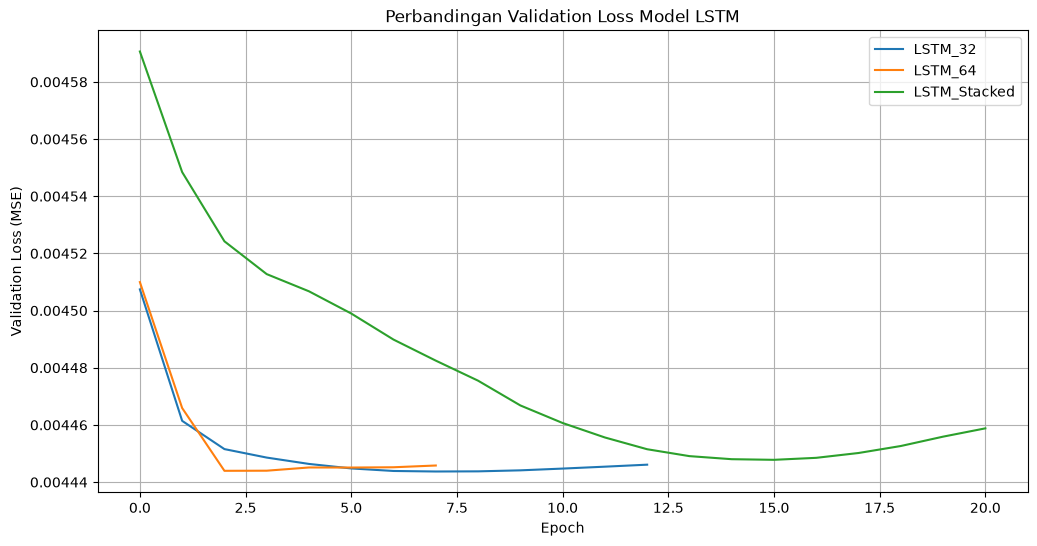

In [33]:
#Code Cell 36 — Grafik loss ketiga model
plt.figure(figsize=(12, 6))

for model_name, history in training_histories.items():
    plt.plot(
        history.history["val_loss"],
        label=model_name
    )

plt.title("Perbandingan Validation Loss Model LSTM")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss (MSE)")
plt.legend()
plt.grid(True)
plt.show()

In [34]:
#Code Cell 37 — Membandingkan performa validation
def inverse_scale(values):
    values = np.array(values).reshape(-1, 1)
    return scaler.inverse_transform(values).flatten()


validation_results = []

for model_name, model in trained_models.items():

    predictions_scaled = model.predict(
        X_val,
        verbose=0
    )

    predictions = inverse_scale(predictions_scaled)
    actual = inverse_scale(y_val)

    rmse = np.sqrt(
        mean_squared_error(actual, predictions)
    )

    mae = mean_absolute_error(actual, predictions)

    validation_results.append({
        "Model": model_name,
        "RMSE_Validation": rmse,
        "MAE_Validation": mae
    })

validation_results_df = pd.DataFrame(validation_results)

validation_results_df = validation_results_df.sort_values(
    "RMSE_Validation"
).reset_index(drop=True)

display(validation_results_df)

,Model,RMSE_Validation,MAE_Validation
0,LSTM_32,3.399720,1.223032
1,LSTM_64,3.399812,1.207434
2,LSTM_Stacked,3.401282,1.217260


In [35]:
#Code Cell 38 — Menentukan model terbaik
best_model_name = validation_results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Model terbaik:", best_model_name)
print(
    "RMSE Validation:",
    validation_results_df.iloc[0]["RMSE_Validation"]
)

print("\nModel terbaik dipilih berdasarkan RMSE validation.")

Model terbaik: LSTM_32
RMSE Validation: 3.39971969795426

Model terbaik dipilih berdasarkan RMSE validation.


# TAHAP 5 - EVALUASI MODEL

Evaluasi dilakukan menggunakan data testing.

Model LSTM terbaik dibandingkan dengan metode
Naive Forecast sebagai baseline.

Metrik evaluasi yang digunakan:
- RMSE
- MAE
- MAPE
- R-squared

MAPE dihitung hanya pada hari dengan jumlah gempa aktual
lebih dari nol karena pembagian dengan nilai nol
tidak dapat dilakukan.

In [36]:
#Code Cell 40 — Prediksi data testing
# Prediksi model LSTM terbaik
test_predictions_scaled = best_model.predict(
    X_test,
    verbose=0
)

# Mengembalikan skala data ke jumlah gempa sebenarnya
y_test_actual = inverse_scale(y_test)
y_test_predicted = inverse_scale(test_predictions_scaled)

# Prediksi baseline: jumlah gempa hari sebelumnya
naive_predictions = data[val_end - 1:n - 1]

print("Jumlah data testing:", len(y_test_actual))
print("Jumlah prediksi LSTM:", len(y_test_predicted))
print("Jumlah prediksi baseline:", len(naive_predictions))

Jumlah data testing: 1900
Jumlah prediksi LSTM: 1900
Jumlah prediksi baseline: 1900


In [37]:
#Code Cell 41 — Fungsi evaluasi
def evaluate_model(y_true, y_pred, model_name):

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mae = mean_absolute_error(y_true, y_pred)

    # MAPE hanya untuk nilai aktual yang lebih dari nol
    nonzero_mask = y_true > 0

    if nonzero_mask.sum() > 0:
        mape = mean_absolute_percentage_error(
            y_true[nonzero_mask],
            y_pred[nonzero_mask]
        ) * 100
    else:
        mape = np.nan

    r2 = r2_score(y_true, y_pred)

    # WAPE menggunakan seluruh data, termasuk hari nol
    wape = (
        np.sum(np.abs(y_true - y_pred))
        / np.sum(y_true)
    ) * 100

    return {
        "Model": model_name,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE_nonzero (%)": mape,
        "WAPE (%)": wape,
        "R2": r2
    }

In [38]:
#Code Cell 42 — Perbandingan hasil evaluasi
lstm_metrics = evaluate_model(
    y_test_actual,
    y_test_predicted,
    best_model_name
)

naive_metrics = evaluate_model(
    y_test_actual,
    naive_predictions,
    "Naive Forecast"
)

evaluation_df = pd.DataFrame([
    lstm_metrics,
    naive_metrics
])

display(evaluation_df)

,Model,RMSE,MAE,MAPE_nonzero (%),WAPE (%),R2
0,LSTM_32,1.518400,1.109084,45.661122,88.28064,-0.015379
1,Naive Forecast,1.967098,1.282105,74.881971,102.05278,-0.704150


In [39]:
#Cell 42A — Statistik prediksi
print("STATISTIK PREDIKSI LSTM")
print("=" * 40)

print("Aktual:")
print(pd.Series(y_test_actual).describe())

print("\nPrediksi:")
print(pd.Series(y_test_predicted).describe())

print("\nJumlah prediksi:")
print("Minimum:", y_test_predicted.min())
print("Maksimum:", y_test_predicted.max())
print("Rata-rata:", y_test_predicted.mean())
print("Median:", np.median(y_test_predicted))
print("Standar deviasi:", y_test_predicted.std())

STATISTIK PREDIKSI LSTM
Aktual:
count    1900.000000
mean        1.256316
std         1.507254
min         0.000000
25%         0.000000
50%         1.000000
75%         2.000000
max        27.000000
dtype: float64

Prediksi:
count    1900.000000
mean        1.561673
std         0.196768
min         1.303747
25%         1.437175
50%         1.521951
75%         1.638095
max         4.569079
dtype: float64

Jumlah prediksi:
Minimum: 1.3037474
Maksimum: 4.569079
Rata-rata: 1.5616733
Median: 1.5219507
Standar deviasi: 0.1967158


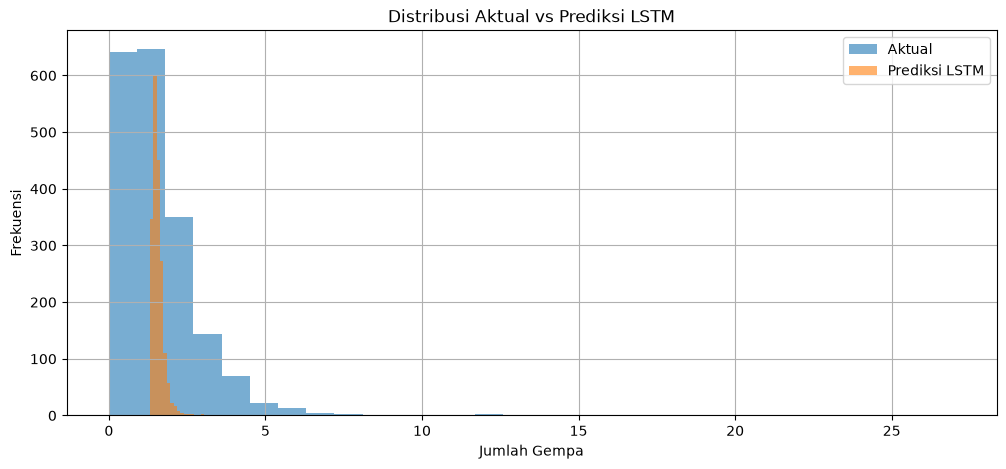

In [40]:
#Cell 42B — Distribusi prediksi
plt.figure(figsize=(12, 5))

plt.hist(
    y_test_actual,
    bins=30,
    alpha=0.6,
    label="Aktual"
)

plt.hist(
    y_test_predicted,
    bins=30,
    alpha=0.6,
    label="Prediksi LSTM"
)

plt.title("Distribusi Aktual vs Prediksi LSTM")
plt.xlabel("Jumlah Gempa")
plt.ylabel("Frekuensi")
plt.legend()
plt.grid(True)
plt.show()

In [41]:
#Cell 42C — Perbandingan rata-rata
print("PERBANDINGAN AKTUAL DAN PREDIKSI")
print("=" * 40)

print(f"Rata-rata aktual  : {y_test_actual.mean():.4f}")
print(f"Rata-rata prediksi: {y_test_predicted.mean():.4f}")

print(f"\nStandar deviasi aktual  : {y_test_actual.std():.4f}")
print(f"Standar deviasi prediksi: {y_test_predicted.std():.4f}")

print(f"\nRata-rata baseline: {naive_predictions.mean():.4f}")

PERBANDINGAN AKTUAL DAN PREDIKSI
Rata-rata aktual  : 1.2563
Rata-rata prediksi: 1.5617

Standar deviasi aktual  : 1.5069
Standar deviasi prediksi: 0.1967

Rata-rata baseline: 1.2563


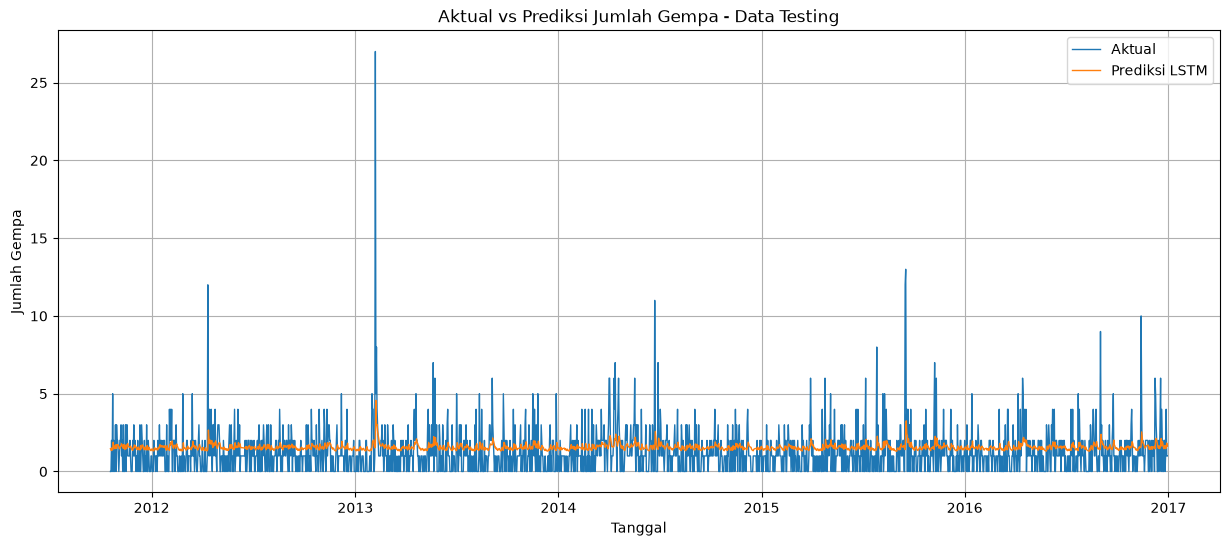

In [42]:
#Code Cell 43 — Grafik aktual vs prediksi
test_dates = daily_df["tanggal"].iloc[val_end:].reset_index(drop=True)

plt.figure(figsize=(15, 6))

plt.plot(
    test_dates,
    y_test_actual,
    label="Aktual",
    linewidth=1
)

plt.plot(
    test_dates,
    y_test_predicted,
    label="Prediksi LSTM",
    linewidth=1
)

plt.title("Aktual vs Prediksi Jumlah Gempa - Data Testing")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Gempa")
plt.legend()
plt.grid(True)
plt.show()

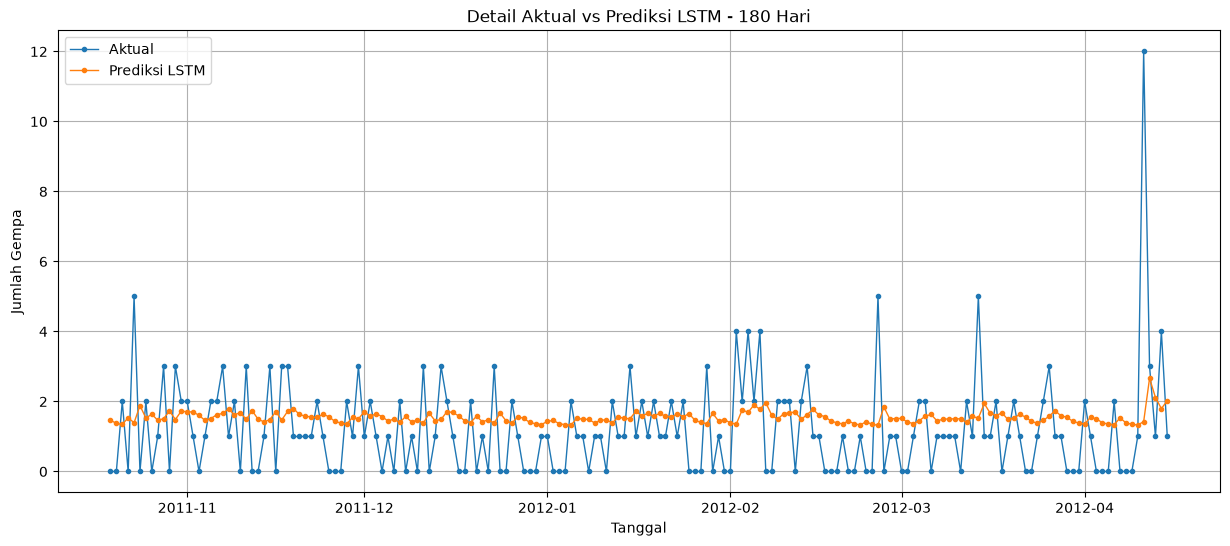

In [43]:
#Code Cell 44 — Grafik perbandingan sebagian data testing
jumlah_hari = 180

plt.figure(figsize=(15, 6))

plt.plot(
    test_dates[:jumlah_hari],
    y_test_actual[:jumlah_hari],
    label="Aktual",
    marker=".",
    linewidth=1
)

plt.plot(
    test_dates[:jumlah_hari],
    y_test_predicted[:jumlah_hari],
    label="Prediksi LSTM",
    marker=".",
    linewidth=1
)

plt.title("Detail Aktual vs Prediksi LSTM - 180 Hari")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Gempa")
plt.legend()
plt.grid(True)
plt.show()

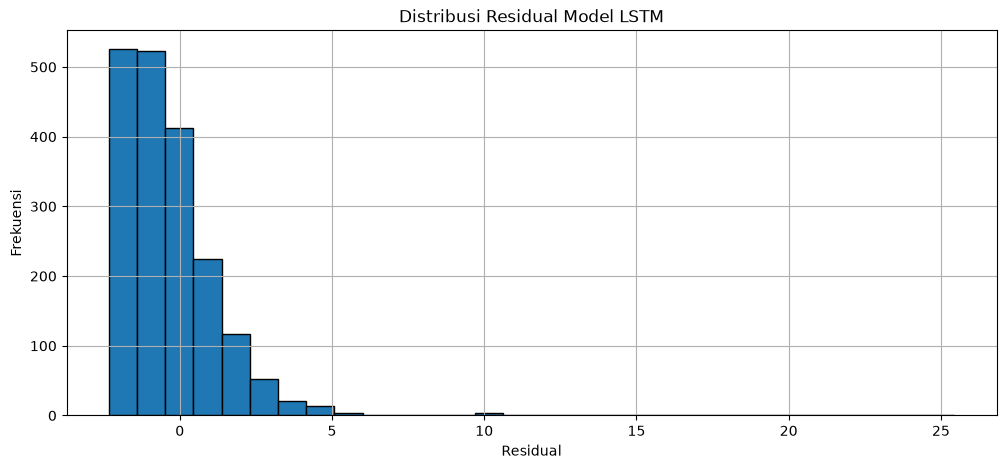

Rata-rata residual: -0.3053575
Standar deviasi residual: 1.4873787


In [44]:
#Code Cell 45 — Grafik residual
residuals = y_test_actual - y_test_predicted

plt.figure(figsize=(12, 5))

plt.hist(
    residuals,
    bins=30,
    edgecolor="black"
)

plt.title("Distribusi Residual Model LSTM")
plt.xlabel("Residual")
plt.ylabel("Frekuensi")
plt.grid(True)
plt.show()

print("Rata-rata residual:", np.mean(residuals))
print("Standar deviasi residual:", np.std(residuals))

# TAHAP 6 - PERAMALAN MASA DEPAN

Pada tahap ini model LSTM digunakan untuk memprediksi
jumlah gempa pada periode setelah tanggal terakhir dataset.

Horizon peramalan yang disediakan:
- 1 hari
- 7 hari
- 14 hari
- 30 hari

Peramalan multi-hari dilakukan menggunakan recursive forecasting.
Hasil prediksi hari sebelumnya digunakan sebagai input
untuk menghasilkan prediksi hari berikutnya.

In [45]:
#Code Cell 47 — Membuat fungsi forecasting
def forecast_future(model, last_sequence, horizon, scaler):

    current_sequence = last_sequence.copy()

    future_predictions = []

    for _ in range(horizon):

        # Bentuk input sesuai kebutuhan LSTM
        input_data = current_sequence.reshape(1, TIMESTEPS, 1)

        # Prediksi dalam skala normalisasi
        prediction_scaled = model.predict(
            input_data,
            verbose=0
        )[0][0]

        # Mengembalikan ke skala jumlah gempa
        prediction_original = scaler.inverse_transform(
            np.array([[prediction_scaled]])
        )[0][0]

        # Jumlah gempa tidak mungkin negatif
        prediction_original = max(0, prediction_original)

        future_predictions.append(prediction_original)

        # Normalisasi kembali hasil prediksi
        next_scaled = scaler.transform(
            np.array([[prediction_original]])
        )[0][0]

        # Geser sequence: buang hari terlama, masukkan prediksi terbaru
        current_sequence = np.append(
            current_sequence[1:],
            next_scaled
        )

    return np.array(future_predictions)

In [46]:
#Code Cell 48 — Menentukan periode prediksi
# Pilih salah satu: 1, 7, 14, atau 30
FORECAST_HORIZON = 30

if FORECAST_HORIZON not in [1, 7, 14, 30]:
    raise ValueError("Horizon harus 1, 7, 14, atau 30 hari.")

# Mengambil 90 hari terakhir
last_sequence = scaled_data[-TIMESTEPS:]

# Melakukan peramalan
future_predictions = forecast_future(
    best_model,
    last_sequence,
    FORECAST_HORIZON,
    scaler
)

# Membuat tanggal masa depan
last_date = daily_df["tanggal"].iloc[-1]

future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=FORECAST_HORIZON,
    freq="D"
)

forecast_df = pd.DataFrame({
    "tanggal": future_dates,
    "prediksi_jumlah_gempa": future_predictions
})

display(forecast_df)

,tanggal,prediksi_jumlah_gempa
0,2016-12-31 00:00:00+00:00,1.569638
1,2017-01-01 00:00:00+00:00,1.609181
2,2017-01-02 00:00:00+00:00,1.623209
3,2017-01-03 00:00:00+00:00,1.629476
4,2017-01-04 00:00:00+00:00,1.633188
5,2017-01-05 00:00:00+00:00,1.635877
6,2017-01-06 00:00:00+00:00,1.637986
7,2017-01-07 00:00:00+00:00,1.639656
8,2017-01-08 00:00:00+00:00,1.640957
9,2017-01-09 00:00:00+00:00,1.641947


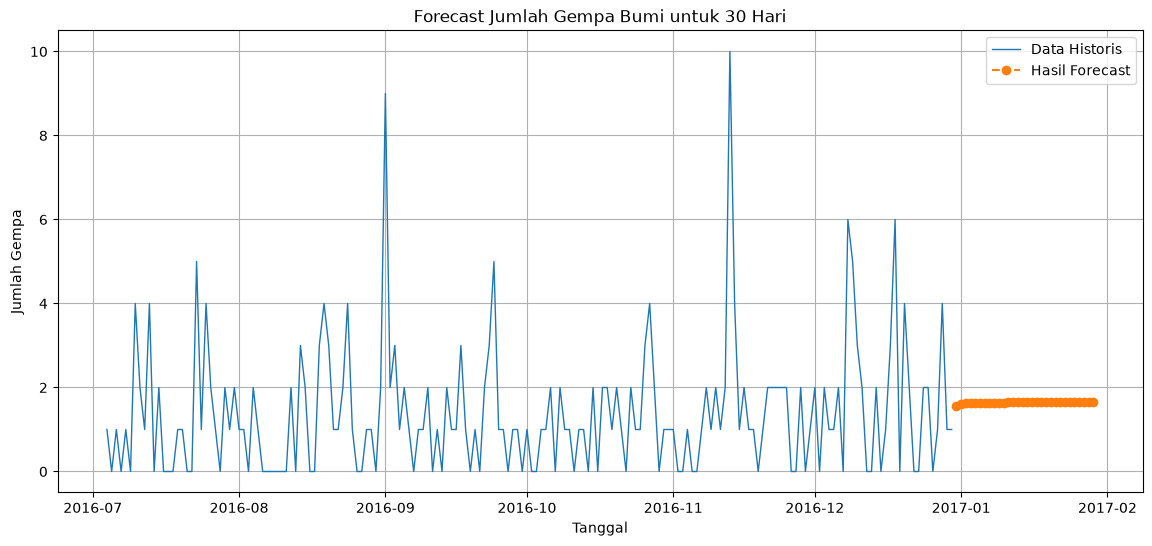

In [47]:
#Code Cell 49 — Grafik peramalan masa depan
plt.figure(figsize=(14, 6))

# Riwayat 180 hari terakhir
history_dates = daily_df["tanggal"].iloc[-180:]
history_values = daily_df["jumlah_gempa"].iloc[-180:]

plt.plot(
    history_dates,
    history_values,
    label="Data Historis",
    linewidth=1
)

plt.plot(
    future_dates,
    future_predictions,
    label="Hasil Forecast",
    marker="o",
    linestyle="--"
)

plt.title(
    f"Forecast Jumlah Gempa Bumi untuk {FORECAST_HORIZON} Hari"
)

plt.xlabel("Tanggal")
plt.ylabel("Jumlah Gempa")
plt.legend()
plt.grid(True)
plt.show()

# TAHAP 7 - PENYIMPANAN MODEL DAN HASIL

Model LSTM terbaik, scaler, hasil evaluasi,
dan hasil forecasting disimpan ke dalam folder proyek.

File yang disimpan akan digunakan kembali
pada tahap pembangunan aplikasi berbasis Flask.

In [48]:
#Code Cell 51 — Menyiapkan folder penyimpanan
MODEL_DIR = PROJECT_DIR / "models"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORT_DIR = PROJECT_DIR / "reports"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Folder model:", MODEL_DIR)
print("Folder data:", PROCESSED_DIR)
print("Folder laporan:", REPORT_DIR)

Folder model: D:\Semester5 ML\TA-04-Earthquake-Forecasting\models
Folder data: D:\Semester5 ML\TA-04-Earthquake-Forecasting\data\processed
Folder laporan: D:\Semester5 ML\TA-04-Earthquake-Forecasting\reports


In [49]:
#Code Cell 53 — Menyimpan hasil evaluasi
evaluation_path = REPORT_DIR / "evaluation_results.csv"

evaluation_df.to_csv(
    evaluation_path,
    index=False
)

validation_path = REPORT_DIR / "validation_comparison.csv"

validation_results_df.to_csv(
    validation_path,
    index=False
)

forecast_path = PROCESSED_DIR / "future_forecast.csv"

forecast_df.to_csv(
    forecast_path,
    index=False
)

print("Hasil evaluasi berhasil disimpan.")
print("Hasil validation berhasil disimpan.")
print("Hasil forecast berhasil disimpan.")

Hasil evaluasi berhasil disimpan.
Hasil validation berhasil disimpan.
Hasil forecast berhasil disimpan.


In [50]:
#Code Cell 54 — Menyimpan informasi model
model_metadata = {
    "project_title": "Peramalan Jumlah Gempa Bumi Signifikan per Hari Menggunakan LSTM",
    "dataset": "USGS Significant Earthquakes 1965-2016",
    "target": "jumlah_gempa",
    "filter_type": "Earthquake",
    "minimum_magnitude": 5.5,
    "frequency": "Daily",
    "timesteps": TIMESTEPS,
    "train_ratio": 0.80,
    "validation_ratio": 0.10,
    "test_ratio": 0.10,
    "best_model": best_model_name,
    "forecast_horizon": FORECAST_HORIZON,
    "total_observations": int(n),
    "training_observations": int(len(train_data)),
    "validation_observations": int(len(val_data)),
    "testing_observations": int(len(test_data))
}

metadata_path = MODEL_DIR / "model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(
        model_metadata,
        file,
        indent=4,
        ensure_ascii=False
    )

print("Metadata berhasil disimpan.")

Metadata berhasil disimpan.


In [51]:
#Code Cell 55 — Memastikan semua file tersedia
print("DAFTAR FILE HASIL PROYEK")
print("=" * 50)

for folder in [MODEL_DIR, PROCESSED_DIR, REPORT_DIR]:

    print(f"\nFolder: {folder.name}")

    for file in sorted(folder.iterdir()):
        if file.is_file():
            print("-", file.name)

DAFTAR FILE HASIL PROYEK

Folder: models
- best_lstm_model.keras
- model_metadata.json
- scaler.joblib

Folder: processed
- earthquake_daily_counts.csv
- future_forecast.csv

Folder: reports
- evaluation_results.csv
- validation_comparison.csv


In [52]:
from pathlib import Path

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Isi folder models:")

for file in MODEL_DIR.iterdir():
    print(file.name)

Isi folder models:
best_lstm_model.keras
model_metadata.json
scaler.joblib


In [53]:
# Memastikan model terbaik masih tersedia
print("Model terpilih:", best_model_name)

# Menyimpan model dalam format Keras
MODEL_PATH = MODEL_DIR / "best_lstm_model.keras"

best_model.save(
    MODEL_PATH
)

print("\nModel berhasil disimpan!")
print("Lokasi:", MODEL_PATH)
print("Ukuran:", round(MODEL_PATH.stat().st_size / (1024 * 1024), 2), "MB")

Model terpilih: LSTM_32

Model berhasil disimpan!
Lokasi: D:\Semester5 ML\TA-04-Earthquake-Forecasting\models\best_lstm_model.keras
Ukuran: 0.07 MB


In [54]:
import joblib
import json

joblib.dump(
    scaler,
    MODEL_DIR / "scaler.joblib"
)

with open(MODEL_DIR / "model_metadata.json", "w", encoding="utf-8") as file:
    json.dump(
        model_metadata,
        file,
        indent=4,
        ensure_ascii=False
    )

print("Scaler dan metadata berhasil disimpan.")

Scaler dan metadata berhasil disimpan.


In [55]:
required_files = [
    "best_lstm_model.keras",
    "scaler.joblib",
    "model_metadata.json"
]

for filename in required_files:
    filepath = MODEL_DIR / filename

    print(
        filename,
        "->",
        "ADA" if filepath.exists() else "TIDAK ADA"
    )

best_lstm_model.keras -> ADA
scaler.joblib -> ADA
model_metadata.json -> ADA


In [56]:
print("HASIL VALIDATION")
display(validation_results_df)

print("\nHASIL EVALUASI TESTING")
display(evaluation_df)

print("\nHASIL FORECAST")
display(forecast_df)

print("\nMODEL TERPILIH")
print(best_model_name)

print("\nRIWAYAT TRAINING")
for name, history in training_histories.items():
    print(name)
    print("Epoch aktual:", len(history.history["loss"]))
    print("Training loss terbaik:", min(history.history["loss"]))
    print("Validation loss terbaik:", min(history.history["val_loss"]))

HASIL VALIDATION


,Model,RMSE_Validation,MAE_Validation
0,LSTM_32,3.399720,1.223032
1,LSTM_64,3.399812,1.207434
2,LSTM_Stacked,3.401282,1.217260



HASIL EVALUASI TESTING


,Model,RMSE,MAE,MAPE_nonzero (%),WAPE (%),R2
0,LSTM_32,1.518400,1.109084,45.661122,88.28064,-0.015379
1,Naive Forecast,1.967098,1.282105,74.881971,102.05278,-0.704150



HASIL FORECAST


,tanggal,prediksi_jumlah_gempa
0,2016-12-31 00:00:00+00:00,1.569638
1,2017-01-01 00:00:00+00:00,1.609181
2,2017-01-02 00:00:00+00:00,1.623209
3,2017-01-03 00:00:00+00:00,1.629476
4,2017-01-04 00:00:00+00:00,1.633188
5,2017-01-05 00:00:00+00:00,1.635877
6,2017-01-06 00:00:00+00:00,1.637986
7,2017-01-07 00:00:00+00:00,1.639656
8,2017-01-08 00:00:00+00:00,1.640957
9,2017-01-09 00:00:00+00:00,1.641947



MODEL TERPILIH
LSTM_32

RIWAYAT TRAINING
LSTM_32
Epoch aktual: 13
Training loss terbaik: 0.0007218265091069043
Validation loss terbaik: 0.004443712532520294
LSTM_64
Epoch aktual: 8
Training loss terbaik: 0.000720960961189121
Validation loss terbaik: 0.004443952348083258
LSTM_Stacked
Epoch aktual: 21
Training loss terbaik: 0.0007224802393466234
Validation loss terbaik: 0.004447796382009983
